# Plots for Football investigations

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import warnings

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
# Helperfunctions
def plot_per_season_per_country(df, y, y_label,fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.ylabel(y_label)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.ylabel(y_label)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()


## Subject data

In [3]:
df_subject = pd.read_csv("data/plot_subject_data.csv", sep=";")

#df_subject[["country","season","matchnumber", "ht_name","at_name","ht_goals","ht_shotsontarget","ht_marketvalue"]].head()
df_subject.head()

,country,season,matchnumber,ht_name,at_name,ht_goals,at_goals,ht_shotsontarget,at_shotsontarget,ht_marketvalue,at_marketvalue
0,ENG,14-15,1,Arsenal,Crystal Palace,2,1,6,2,415000000,97000000
1,ENG,14-15,1,Burnley,Chelsea,1,3,2,3,53000000,557000000
2,ENG,14-15,1,Leicester,Everton,2,2,3,3,67000000,183000000
3,ENG,14-15,1,Liverpool,Southampton,2,1,5,6,325000000,210000000
4,ENG,14-15,1,Man Utd,Swansea,1,2,5,4,505000000,131000000


## Homefield advantage

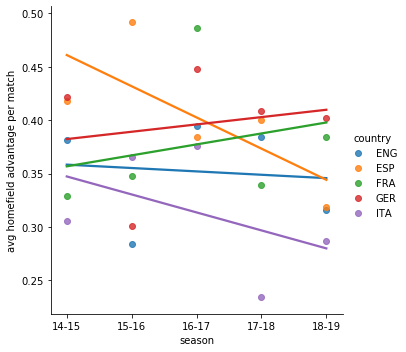

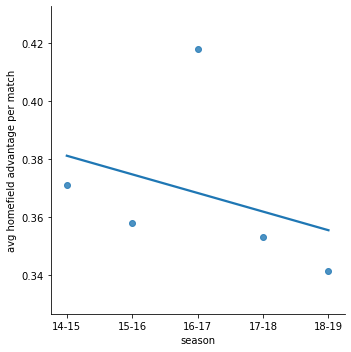

In [4]:
df_homefield = pd.read_csv('data/plot_homefield_adv.csv', sep=';')
plot_per_season_per_country(df_homefield, y="homefield_adv_per_match",
                            y_label="avg homefield advantage per match")


## Goalamount per match

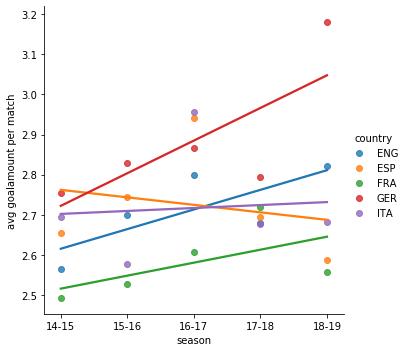

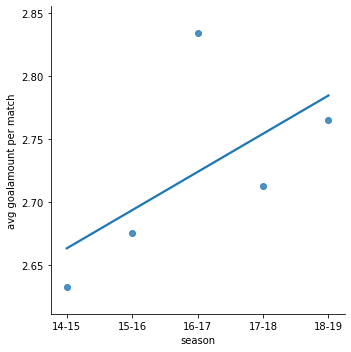

In [5]:
df_goalamount = pd.read_csv('data/plot_goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, y="goalamount_per_match",y_label="avg goalamount per match")


## Goalchances per match

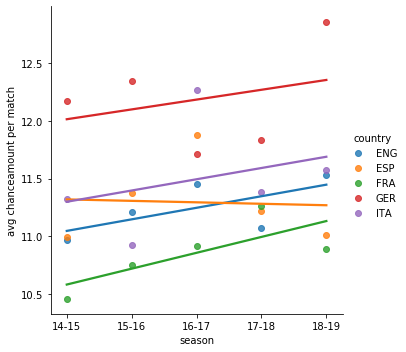

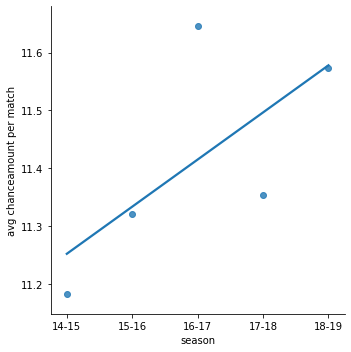

In [6]:
df_chances = pd.read_csv('data/plot_chances.csv', sep=';')
plot_per_season_per_country(df_chances, y="chances_per_match", y_label="avg chanceamount per match")


## Market value 

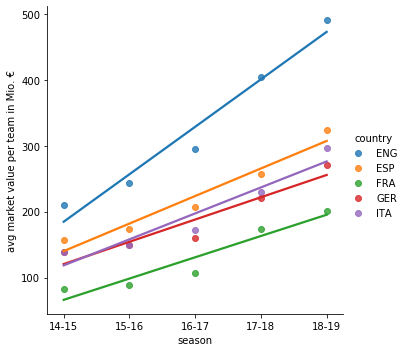

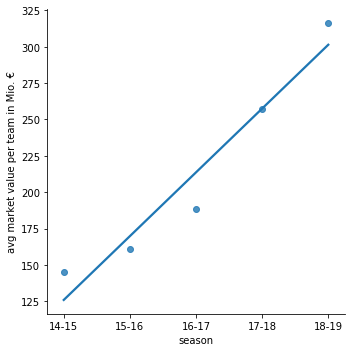

In [7]:
df_market_value = pd.read_csv('data/plot_market_value.csv', sep=';')
plot_per_season_per_country(df_market_value, y="avg_market_value_in_mio_euro", y_label="avg market value per team in Mio. €")


## Market value variance

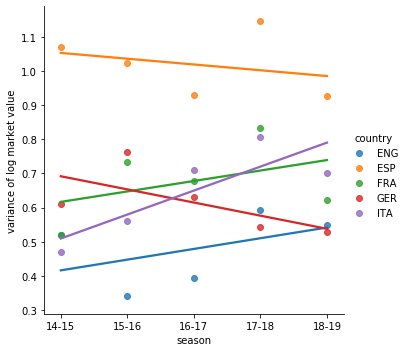

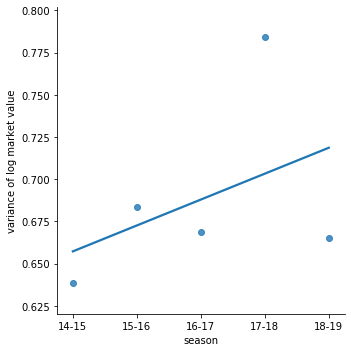

In [8]:
df_market_value_variance = pd.read_csv(
    'data/plot_ln_market_value_variance.csv', sep=';')
plot_per_season_per_country(
    df_market_value_variance, y="ln_market_value_variance", y_label="variance of log market value")


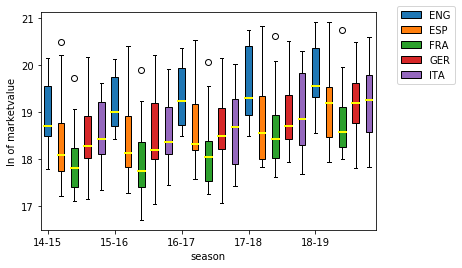

In [9]:

market_value_raw_df = pd.read_csv("data/plot_market_value_raw.csv",sep=";")

leagues = ["ENG", "ESP", "FRA", "GER", "ITA"]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

boxes = []

for season in range(14,19):
    for league in leagues:
        boxes.append(market_value_raw_df.loc[(market_value_raw_df["country"] == league) & (
            market_value_raw_df["season"] == season)]["ln_market_value"])

box_plot = plt.boxplot(boxes, patch_artist=True,
                       medianprops=dict(color='yellow',linewidth='2'))

i = 0
for box in box_plot["boxes"]:
    box.set(facecolor=colors[i % len(colors)])
    i += 1

plt.xticks([1, 6, 11, 16, 21], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.legend([box_plot["boxes"][0], box_plot["boxes"][1], box_plot["boxes"]
            [2], box_plot["boxes"][3], box_plot["boxes"][4],], leagues, bbox_to_anchor=(1.05, 1.05))

plt.xlabel("season")
plt.ylabel("ln of marketvalue")
plt.show()


## Correlation Matrix - Heuers features vs raw

In [10]:
def plot_correlationmatrix(df, threshold=0):
    correlation_matrix = df.corr()
    r = []
    for w in np.round(correlation_matrix.values.reshape(-1), 2):
        if w > threshold or w < -threshold:
            r.append(str(w))
        else:
            r.append("")
    r = np.array(r).reshape(len(df.columns), len(df.columns))
    f, ax = plt.subplots(figsize=(9, 6))
    sns.heatmap(correlation_matrix, annot=r, linewidths=.1, ax=ax, fmt="s",
                cmap=sns.diverging_palette(150, 275, s=80, l=55, n=9), vmin=-1, vmax=1)




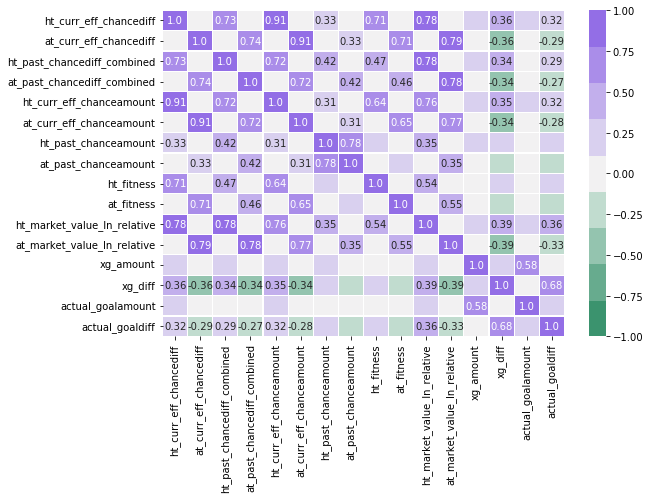

In [11]:
df_matches = pd.read_csv("data/plot_matches.csv", sep=";")
all_features = ["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined", "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                "ht_past_chanceamount", "at_past_chanceamount", "ht_fitness", "at_fitness","ht_market_value_ln_relative", "at_market_value_ln_relative", "xg_amount", "xg_diff", "actual_goalamount", "actual_goaldiff"]
plot_correlationmatrix(
    df_matches[all_features], threshold=0.25)
